# K-Means Clustering

In [22]:
# Importing libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from tabulate import tabulate

In [2]:
# Importing Dataset (For Colab)
# from google.colab import drive

# drive.mount("/content/drive")

# data_way = "/content/drive/MyDrive/TechIstanbul/musteri_segmentasyonu.csv"

# data = pd.read_csv(data_way)

data = pd.read_csv("musteri_segmentasyonu.csv")

X = data[["yillik_gelir", "harcama_puani"]]

In [3]:
# Parameters
k_values = range(1, 11)
inertia_list = []
silhouette_list = []
table = []

In [4]:
# Data transformation
X_scaler = StandardScaler()
X_scaled = X_scaler.fit_transform(X)

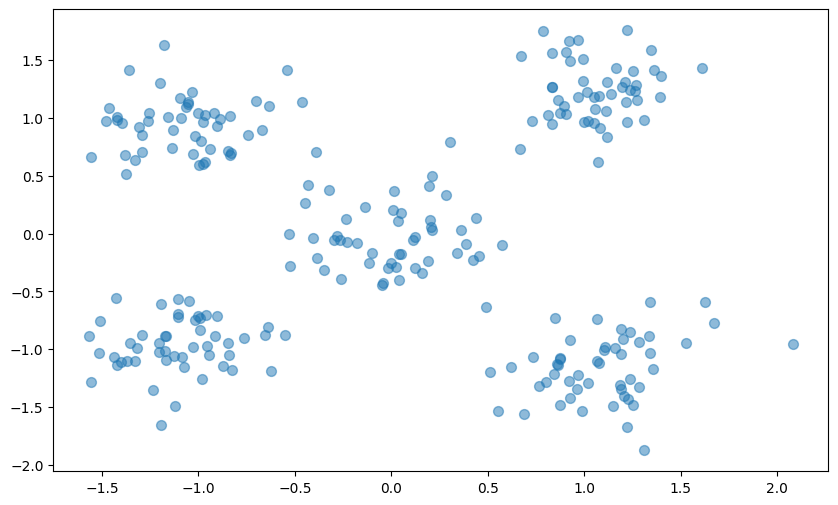

In [5]:
# Data virtualization (first step)
plt.figure(figsize=(10, 6))

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=50, alpha=0.5)
plt.show()

In [6]:
# Analyzing the Variation of Inertia and Silhouette Scores Across Different K Values
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=36, n_init=10)
    kmeans.fit(X_scaled)
    inertia_list.append(kmeans.inertia_)

    if k == 1:
        silhouette_list.append(None)
    else:
        silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))
    table.append([k, inertia_list[k - 1], silhouette_list[k - 1]])

/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero 

In [7]:
print(
    "Analyzing the Variation of Inertia and Silhouette Scores Across Different K Values:\n",
    tabulate(
        table,
        headers=["K value", "Inertia", "Silhouette score"],
        tablefmt="simple",
        numalign="center",
    ),
)

Analyzing the Variation of Inertia and Silhouette Scores Across Different K Values:
  K value    Inertia    Silhouette score
---------  ---------  ------------------
    1         500
    2       292.55         0.397748
    3       160.515        0.511269
    4       81.301         0.596076
    5       33.2065        0.680051
    6       29.7011        0.620632
    7       26.9688        0.549657
    8       24.5573        0.49186
    9       22.488         0.486655
   10       20.3869        0.351973


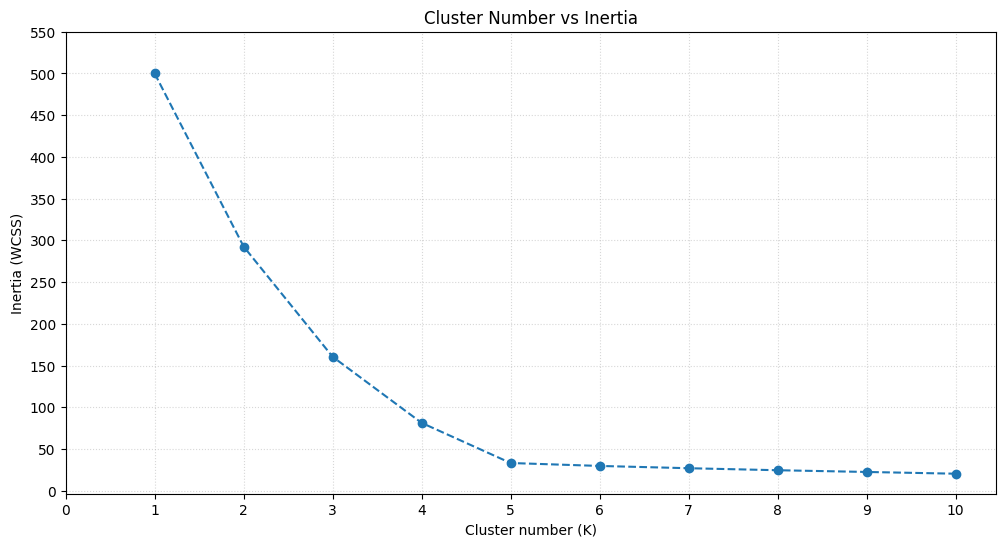

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(k_values, inertia_list, linestyle="--", marker="o")
plt.xlabel("Cluster number (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Cluster Number vs Inertia")
plt.xticks(np.arange(0, max(k_values) + 1, 1))
plt.yticks(np.arange(0, max(inertia_list) + 50, 50))
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

In [ ]:
print(
    "The Variation of Inertia and Silhouette Scores Across Different K Value:\n",
    tabulate(
        table,
        headers=["K value", "Inertia", "Silhouette score"],
        tablefmt="simple",
        numalign="center",
    ),
)


In [9]:
# Determining the Optimal K Value
for k in k_values:
    if k == 1:
        pass
    else:
        abs(
            int(
                (
                    (inertia_list[k] - inertia_list[k - 1])
                    / (inertia_list[k] + inertia_list[k - 1])
                )
                * 100
            )
        )

        if (
            abs(
                int(
                    (
                        (inertia_list[k] - inertia_list[k - 1])
                        / (inertia_list[k] + inertia_list[k - 1])
                    )
                    * 100
                )
            )
            == 5
        ):
            k_opt = k
            break

In [10]:
# Determine the optimum kmeans
kmeans_opt = KMeans(n_clusters=k_opt, random_state=36, n_init=10)
cluster = kmeans_opt.fit(X_scaled)

labels = cluster.labels_
centers = cluster.cluster_centers_

In [11]:
# Revers tranformation to original values
X_original = X_scaler.inverse_transform(X_scaled)
centers_original = X_scaler.inverse_transform(centers)

df = pd.DataFrame(X_original, columns=["Annual Income", "Spending Score"])

In [12]:
# Prepareing data for virtualization
df["cluster"] = labels

cluster_names = {}
for i in range(k_opt):
    cluster_names[i] = f"Cluster {i + 1}"

df["cluster_name"] = df["cluster"].map(cluster_names)

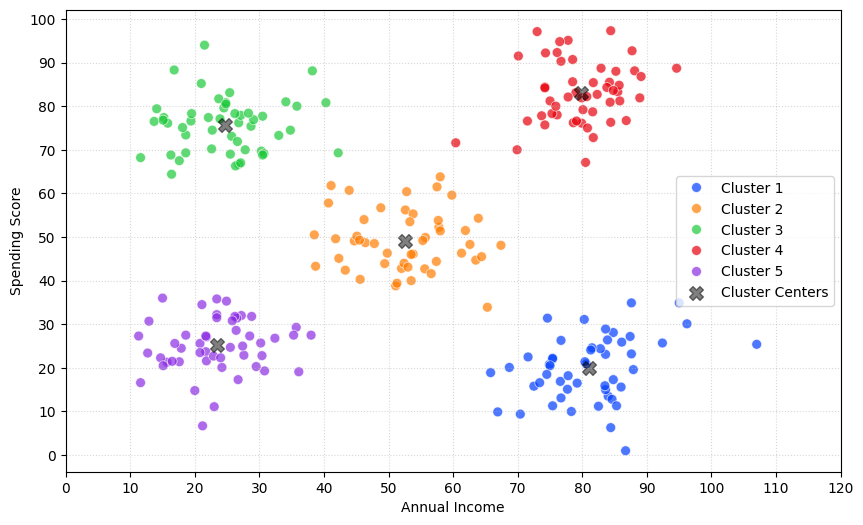

In [30]:
cluster_order = [f"Cluster {i + 1}" for i in range(k_opt)]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Annual Income",
    y="Spending Score",
    hue="cluster_name",
    hue_order=cluster_order,
    palette="bright",
    s=50,
    alpha=0.7,
)


plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    c="black",
    s=100,
    alpha=0.5,
    label="Cluster Centers",
    marker="X",
)
plt.legend(loc="right")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.grid(True, linestyle=":", alpha=0.5)
plt.xticks(np.arange(0, max(df["Annual Income"]) + 20, 10))
plt.yticks(np.arange(0, max(df["Spending Score"]) + 10, 10))
plt.show()